In [1]:
import os
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

record = wfdb.rdrecord('100', pn_dir='mitdb')
fs = record.fs                     # 360 Hz
ecg = record.p_signal[:, 0]        # MLII lead
t = np.arange(len(ecg)) / fs

os.makedirs('figures', exist_ok=True)
print("Loaded", len(ecg), "samples at", fs, "Hz")

Loaded 650000 samples at 360 Hz


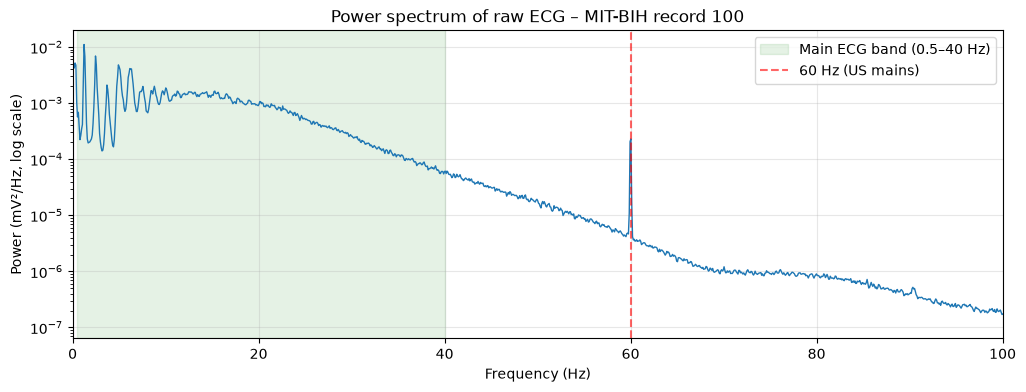

In [2]:
# Welch's method: estimates how much signal power is at each frequency
f, pxx = signal.welch(ecg, fs=fs, nperseg=4096)

plt.figure(figsize=(12, 4))
plt.semilogy(f, pxx, linewidth=1)
plt.axvspan(0.5, 40, color='green', alpha=0.1, label='Main ECG band (0.5–40 Hz)')
plt.axvline(60, color='red', linestyle='--', alpha=0.6, label='60 Hz (US mains)')
plt.xlim(0, 100)
plt.title("Power spectrum of raw ECG – MIT-BIH record 100")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (mV²/Hz, log scale)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('figures/03_raw_power_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# 1) Notch filter at 60 Hz – removes power-line interference
f0, Q = 60.0, 30.0                          # Q = how narrow the notch is
b_notch, a_notch = signal.iirnotch(f0, Q, fs=fs)
ecg_notched = signal.filtfilt(b_notch, a_notch, ecg)

# 2) Band-pass 0.5–40 Hz (4th-order Butterworth)
#    removes baseline wander (<0.5 Hz) and high-frequency noise (>40 Hz)
sos_bp = signal.butter(4, [0.5, 40], btype='bandpass', fs=fs, output='sos')
ecg_filt = signal.sosfiltfilt(sos_bp, ecg_notched)

print(f"Raw mean:      {ecg.mean():.3f} mV")
print(f"Filtered mean: {ecg_filt.mean():.3f} mV")

Raw mean:      -0.306 mV
Filtered mean: 0.000 mV


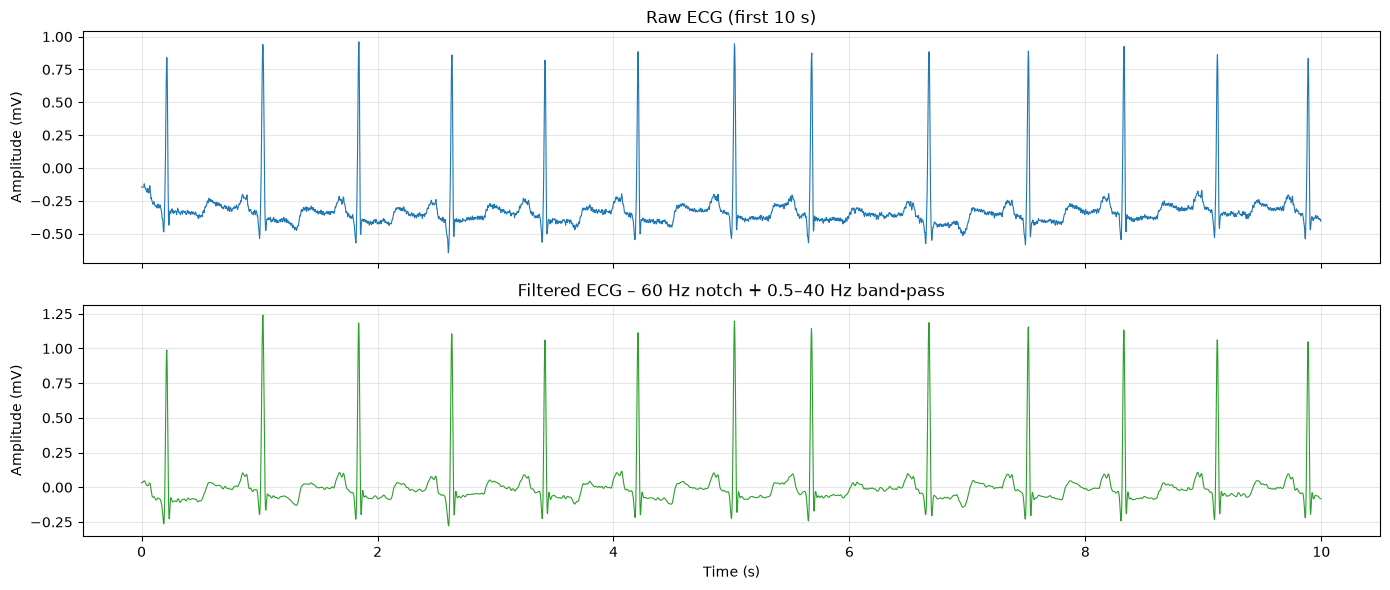

In [4]:
n = 10 * fs
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(t[:n], ecg[:n], linewidth=0.8)
axes[0].set_title("Raw ECG (first 10 s)")

axes[1].plot(t[:n], ecg_filt[:n], linewidth=0.8, color='tab:green')
axes[1].set_title("Filtered ECG – 60 Hz notch + 0.5–40 Hz band-pass")
axes[1].set_xlabel("Time (s)")

for ax in axes:
    ax.set_ylabel("Amplitude (mV)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/04_raw_vs_filtered_time.png', dpi=150, bbox_inches='tight')
plt.show()

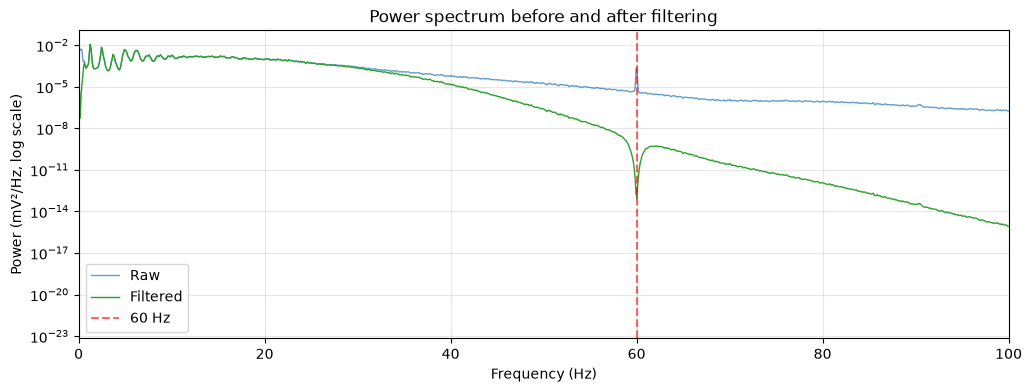

In [5]:
f2, pxx_filt = signal.welch(ecg_filt, fs=fs, nperseg=4096)

plt.figure(figsize=(12, 4))
plt.semilogy(f, pxx, linewidth=1, alpha=0.7, label='Raw')
plt.semilogy(f2, pxx_filt, linewidth=1, color='tab:green', label='Filtered')
plt.axvline(60, color='red', linestyle='--', alpha=0.6, label='60 Hz')
plt.xlim(0, 100)
plt.title("Power spectrum before and after filtering")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (mV²/Hz, log scale)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('figures/05_power_spectrum_before_after.png', dpi=150, bbox_inches='tight')
plt.show()

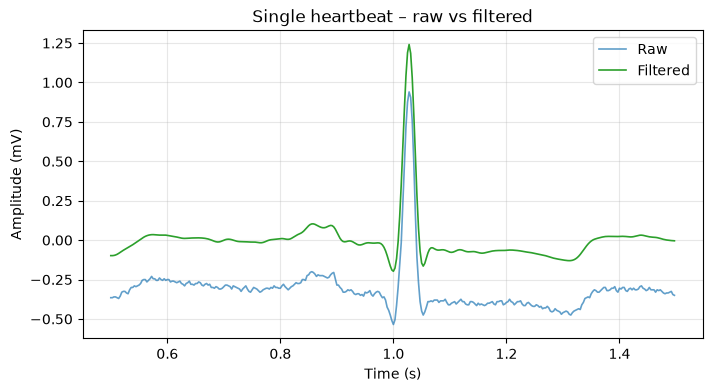

In [6]:
start, end = int(0.5 * fs), int(1.5 * fs)

plt.figure(figsize=(8, 4))
plt.plot(t[start:end], ecg[start:end], linewidth=1.2, alpha=0.7, label='Raw')
plt.plot(t[start:end], ecg_filt[start:end], linewidth=1.2, color='tab:green', label='Filtered')
plt.title("Single heartbeat – raw vs filtered")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('figures/06_heartbeat_raw_vs_filtered.png', dpi=150, bbox_inches='tight')
plt.show()